# Regression Metrics

Compare MAE, MSE, RMSE, and R² on a regression problem.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
X, y = make_regression(n_samples=400, n_features=5, noise=25, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
models = {'Mean baseline': DummyRegressor(), 'Linear regression': LinearRegression()}
rows, predictions = [], {}
for name, model in models.items():
    model.fit(X_train, y_train); pred = model.predict(X_test); predictions[name] = pred
    rows.append({'model': name, 'MAE': mean_absolute_error(y_test, pred), 'MSE': mean_squared_error(y_test, pred), 'RMSE': np.sqrt(mean_squared_error(y_test, pred)), 'R2': r2_score(y_test, pred)})
pd.DataFrame(rows).round(3)

,model,MAE,MSE,RMSE,R2
0,Mean baseline,77.040,9283.972,96.353,-0.011
1,Linear regression,21.291,691.041,26.288,0.925


## Actual versus predicted values

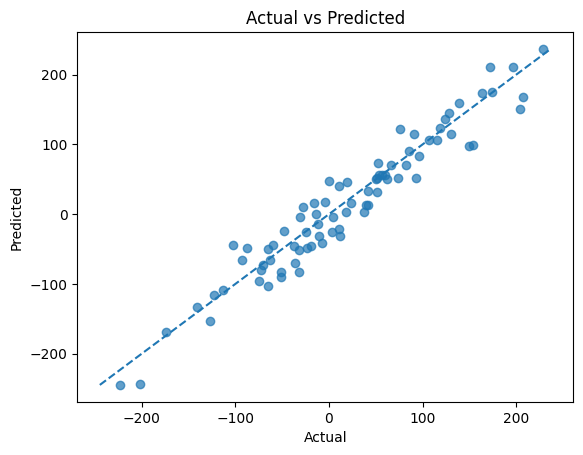

In [2]:
pred = predictions['Linear regression']
plt.scatter(y_test, pred, alpha=0.7)
lo, hi = min(y_test.min(), pred.min()), max(y_test.max(), pred.max())
plt.plot([lo, hi], [lo, hi], '--')
plt.xlabel('Actual'); plt.ylabel('Predicted'); plt.title('Actual vs Predicted'); plt.show()

## Residual analysis
A residual is the actual target minus the prediction. Patterns can indicate that a model misses structure.

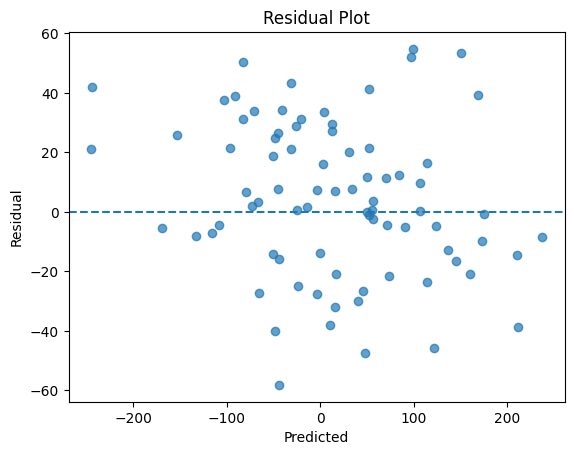

In [3]:
residuals = y_test - predictions['Linear regression']
plt.scatter(predictions['Linear regression'], residuals, alpha=0.7)
plt.axhline(0, linestyle='--'); plt.xlabel('Predicted'); plt.ylabel('Residual'); plt.title('Residual Plot'); plt.show()

## Metric interpretation
- **MAE**: average absolute error, in target units.
- **MSE**: squares errors, giving large errors greater influence.
- **RMSE**: square root of MSE, in target units.
- **R²**: relative fit against a mean-prediction baseline; it can be negative.